<a href="https://colab.research.google.com/github/nurfnick/Numerical_Methods/blob/master/Module_6_Regression/VibeCodeMultipleRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prompt:



---

I want to vibe code a non-linear regression model with synthetic data. I am interested in adoption of cell phones across the world by country. My model should be logistic and look at percent of poluation that has adopted the technology. I want to use time, electricity rates, world cup preformance, cash usage and literacy rates as my prediction variables. My model should include interaction effects. The model should include cross validation.

### 1. Synthetic Data Generation
We will create a synthetic dataset spanning several countries and years. The target variable is the cell phone adoption rate (percentage of the population, bounded between 0 and 1). We will generate the following predictors:
* `time`: Years since a baseline (e.g., year 2000).
* `electricity_rate`: Percentage of population with access to electricity.
* `world_cup_performance`: A metric indicating historical success or performance in the FIFA World Cup.
* `cash_usage`: Percentage of transactions done in cash (typically negatively correlated with digital/mobile adoption).
* `literacy_rate`: Percentage of literate population.

We will define a true underlying non-linear logistic relationship including interactions, then add some noise.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic panel data
countries = ['Country_A', 'Country_B', 'Country_C', 'Country_D', 'Country_E', 'Country_F', 'Country_G', 'Country_H', 'Country_I', 'Country_J']
years = np.arange(2000, 2024)

data_rows = []
for country in countries:
    # Define country-specific baselines
    base_electricity = np.random.uniform(40, 95)
    base_literacy = np.random.uniform(50, 99)
    base_cash = np.random.uniform(30, 90)
    wc_perf = np.random.uniform(0, 100) # Static historical performance score

    for t_idx, year in enumerate(years):
        t = year - 2000 # normalized time

        # Features evolving slightly over time
        electricity = np.clip(base_electricity + t * np.random.uniform(0.2, 1.5), 0, 100)
        literacy = np.clip(base_literacy + t * np.random.uniform(0.1, 0.8), 0, 100)
        cash = np.clip(base_cash - t * np.random.uniform(0.5, 2.0), 5, 100)

        # Let's model a latent driver 'z' with main effects and interactions
        # e.g., Interaction between electricity and literacy, and cash and time
        z = (-3.0
             + 0.15 * t
             + 0.03 * electricity
             + 0.02 * literacy
             - 0.04 * cash
             + 0.005 * wc_perf
             + 0.001 * (electricity * literacy)
             - 0.002 * (cash * t))

        # Apply logistic function to get adoption rate (0 to 1)
        adoption_rate = 1 / (1 + np.exp(-z))

        # Add Beta-like or Gaussian noise, clipped to [0, 1]
        noise = np.random.normal(0, 0.03)
        adoption_rate = np.clip(adoption_rate + noise, 0.0, 1.0)

        data_rows.append({
            'country': country,
            'year': year,
            'time': t,
            'electricity_rate': electricity,
            'world_cup_performance': wc_perf,
            'cash_usage': cash,
            'literacy_rate': literacy,
            'adoption_rate': adoption_rate
        })

df = pd.DataFrame(data_rows)
display(df.head())


,country,year,time,electricity_rate,world_cup_performance,cash_usage,literacy_rate,adoption_rate
0,Country_A,2000,0,60.599707,59.865848,73.919637,96.585001,0.989392
1,Country_A,2001,1,61.720201,59.865848,71.964772,96.699410,1.000000
2,Country_A,2002,2,63.164057,59.865848,72.374162,97.082276,0.970531
3,Country_A,2003,3,63.246257,59.865848,71.109105,97.792086,0.961469
4,Country_A,2004,4,64.581342,59.865848,70.166769,97.375584,0.969930


### 2. Formulating and Fitting the Non-Linear Logistic Regression Model
We define a logistic model where the sigmoid's exponent is a linear combination of our main predictors, interactions, and a constant offset. We will use `scipy.optimize.curve_fit` to estimate the parameters.

In [10]:
# Define predictors and target
# We will explicitly construct interaction features
df['elec_literacy_interaction'] = df['electricity_rate'] * df['literacy_rate']
df['cash_time_interaction'] = df['cash_usage'] * df['time']

feature_cols = [
    'time', 'electricity_rate', 'world_cup_performance',
    'cash_usage', 'literacy_rate', 'elec_literacy_interaction',
    'cash_time_interaction'
]

X = df[feature_cols].values
y = df['adoption_rate'].values

# Define logistic non-linear function
# x_data has shape (N, num_features)
def logistic_model(x_data, beta0, beta1, beta2, beta3, beta4, beta5, beta6, beta7):
    # Linear combination of features
    z = (beta0
         + beta1 * x_data[:, 0]  # time
         + beta2 * x_data[:, 1]  # electricity_rate
         + beta3 * x_data[:, 2]  # world_cup_performance
         + beta4 * x_data[:, 3]  # cash_usage
         + beta5 * x_data[:, 4]  # literacy_rate
         + beta6 * x_data[:, 5]  # elec_literacy_interaction
         + beta7 * x_data[:, 6]) # cash_time_interaction
    return 1 / (1 + np.exp(-z))

# Initial guess for curve_fit
initial_guess = [0.0] * 8

# Fit on the entire dataset to inspect coefficients
popt, pcov = curve_fit(logistic_model, X, y, p0=initial_guess, maxfev=10000)

print("Fitted Parameters:")
for col, val in zip(['intercept'] + feature_cols, popt):
    print(f"{col:>30}: {val:.6f}")


Fitted Parameters:
                     intercept: -5.875373
                          time: 0.301479
              electricity_rate: 0.062557
         world_cup_performance: -0.012130
                    cash_usage: -0.013692
                 literacy_rate: 0.042843
     elec_literacy_interaction: 0.000648
         cash_time_interaction: -0.003658


### 3. Cross-Validation Evaluation
We perform a K-Fold cross-validation to assess generalization of our non-linear logistic model, tracking Mean Squared Error (MSE) and $R^2$ score across folds.

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
mses = []
r2s = []

print("Starting 5-Fold Cross-Validation...\n")
for fold, (train_idx, test_idx) in enumerate(kf.split(X)):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Fit model
    popt_fold, _ = curve_fit(logistic_model, X_train, y_train, p0=initial_guess, maxfev=10000)

    # Predict
    preds = logistic_model(X_test, *popt_fold)

    # Calculate metrics
    mse = mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    mses.append(mse)
    r2s.append(r2)
    print(f"Fold {fold + 1} - MSE: {mse:.5f}, R2: {r2:.5f}")

print(f"\nAverage CV MSE: {np.mean(mses):.5f}")
print(f"Average CV R2: {np.mean(r2s):.5f}")


Starting 5-Fold Cross-Validation...

Fold 1 - MSE: 0.00055, R2: 0.94147
Fold 2 - MSE: 0.00074, R2: 0.84849
Fold 3 - MSE: 0.00072, R2: 0.92616
Fold 4 - MSE: 0.00042, R2: 0.74822
Fold 5 - MSE: 0.00031, R2: 0.71239

Average CV MSE: 0.00055
Average CV R2: 0.83535


### 4. Visualization of Fit
Finally, let's visualize the true adoption rates versus our model's predictions over time for a sample of countries.

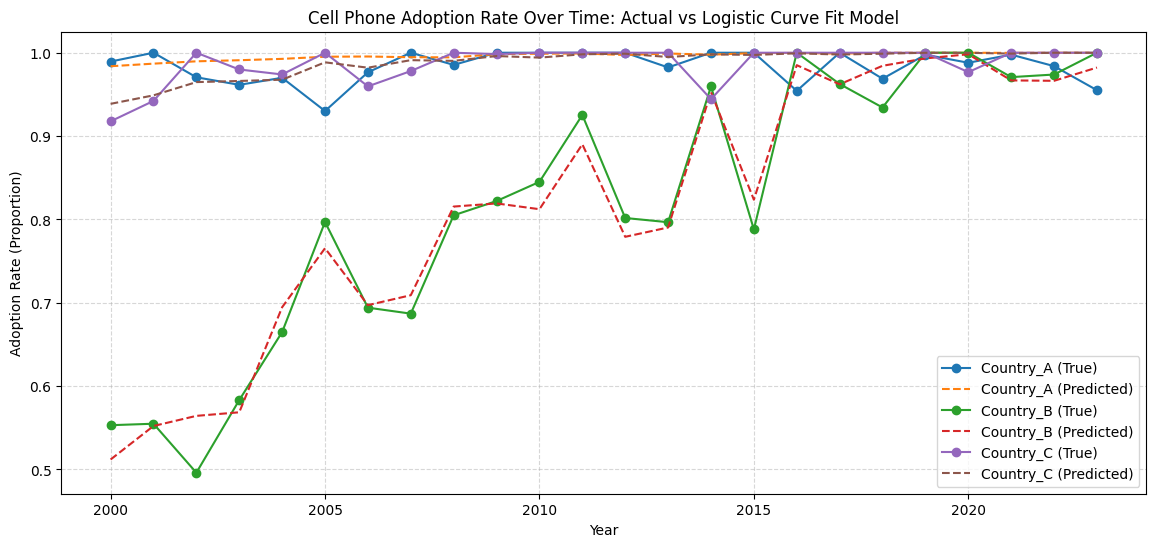

In [12]:
df['predicted_adoption'] = logistic_model(X, *popt)

plt.figure(figsize=(14, 6))
sample_countries = countries[:3]

for i, country in enumerate(sample_countries):
    country_df = df[df['country'] == country].sort_values('year')
    plt.plot(country_df['year'], country_df['adoption_rate'], 'o-', label=f'{country} (True)')
    plt.plot(country_df['year'], country_df['predicted_adoption'], '--', label=f'{country} (Predicted)')

plt.title('Cell Phone Adoption Rate Over Time: Actual vs Logistic Curve Fit Model')
plt.xlabel('Year')
plt.ylabel('Adoption Rate (Proportion)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


Prompt



---

Okay this is a good start. I want the world cup preformance to be categorical data. It should be like failed to qualify, first place, did not make knock out stage, etc. Then there should be a transform on that data.

### 5. Categorical World Cup Performance & Transformation
We will redefine `world_cup_performance` as a categorical feature with categories such as:
* `'Winner'`
* `'Runner-up'`
* `'Knockout stage'`
* `'Group stage'`
* `'Failed to qualify'`

We will then transform this categorical column into numeric values using a mapped dict representing the technological "vibe index" or optimism effect associated with soccer achievements in each country, and update our logistic model accordingly.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

# Define the possible categories and their numerical mappings (impact on adoption)
wc_categories = ['Winner', 'Runner-up', 'Knockout stage', 'Group stage', 'Failed to qualify']
wc_impact_map = {
    'Winner': 1.5,
    'Runner-up': 1.0,
    'Knockout stage': 0.5,
    'Group stage': 0.0,
    'Failed to qualify': -0.8
}

countries = ['Country_A', 'Country_B', 'Country_C', 'Country_D', 'Country_E', 'Country_F', 'Country_G', 'Country_H', 'Country_I', 'Country_J']
years = np.arange(2000, 2024)

# Assign a static World Cup category to each country
country_wc_status = {country: np.random.choice(wc_categories) for country in countries}

data_rows = []
for country in countries:
    base_electricity = np.random.uniform(40, 95)
    base_literacy = np.random.uniform(50, 99)
    base_cash = np.random.uniform(30, 90)

    wc_cat = country_wc_status[country]
    wc_impact = wc_impact_map[wc_cat] # Numeric transformation from category

    for t_idx, year in enumerate(years):
        t = year - 2000

        electricity = np.clip(base_electricity + t * np.random.uniform(0.2, 1.5), 0, 100)
        literacy = np.clip(base_literacy + t * np.random.uniform(0.1, 0.8), 0, 100)
        cash = np.clip(base_cash - t * np.random.uniform(0.5, 2.0), 5, 100)

        # Latent score including categorical World Cup impact
        z = (-3.0
             + 0.15 * t
             + 0.03 * electricity
             + 0.02 * literacy
             - 0.04 * cash
             + 0.3 * wc_impact # Influence of WC category mapping
             + 0.001 * (electricity * literacy)
             - 0.002 * (cash * t))

        adoption_rate = np.clip(1 / (1 + np.exp(-z)) + np.random.normal(0, 0.03), 0.0, 1.0)

        data_rows.append({
            'country': country,
            'year': year,
            'time': t,
            'electricity_rate': electricity,
            'world_cup_status': wc_cat,
            'cash_usage': cash,
            'literacy_rate': literacy,
            'adoption_rate': adoption_rate
        })

df_cat = pd.DataFrame(data_rows)
display(df_cat.head())


,country,year,time,electricity_rate,world_cup_status,cash_usage,literacy_rate,adoption_rate
0,Country_A,2000,0,73.061326,Group stage,31.235070,84.695556,0.983151
1,Country_A,2001,1,73.656841,Group stage,30.087152,85.162886,0.983727
2,Country_A,2002,2,74.218521,Group stage,29.816588,85.752150,0.970915
3,Country_A,2003,3,75.439999,Group stage,28.836538,86.644426,0.956346
4,Country_A,2004,4,76.535345,Group stage,28.956367,86.754317,0.964444


In [14]:
# Transform categorical column to numerical mapped column
df_cat['world_cup_numeric'] = df_cat['world_cup_status'].map(wc_impact_map)

# Create interactions
df_cat['elec_literacy_interaction'] = df_cat['electricity_rate'] * df_cat['literacy_rate']
df_cat['cash_time_interaction'] = df_cat['cash_usage'] * df_cat['time']

feature_cols_cat = [
    'time', 'electricity_rate', 'world_cup_numeric',
    'cash_usage', 'literacy_rate', 'elec_literacy_interaction',
    'cash_time_interaction'
]

X_cat = df_cat[feature_cols_cat].values
y_cat = df_cat['adoption_rate'].values

# Model training and optimization using scipy curve_fit
initial_guess_cat = [0.0] * 8
popt_cat, _ = curve_fit(logistic_model, X_cat, y_cat, p0=initial_guess_cat, maxfev=10000)

print("Fitted Parameters (with Categorical WC Mapping):")
for col, val in zip(['intercept'] + feature_cols_cat, popt_cat):
    print(f"{col:>30}: {val:.6f}")


Fitted Parameters (with Categorical WC Mapping):
                     intercept: -4.381660
                          time: 0.115357
              electricity_rate: 0.064023
             world_cup_numeric: 0.520336
                    cash_usage: -0.046028
                 literacy_rate: 0.042403
     elec_literacy_interaction: 0.000538
         cash_time_interaction: -0.001310


In [15]:
# 5-Fold Cross-Validation on the new model structure
kf_cat = KFold(n_splits=5, shuffle=True, random_state=42)
mses_cat = []
r2s_cat = []

print("Starting 5-Fold CV on the model with mapped categorical performance:\n")
for fold, (train_idx, test_idx) in enumerate(kf_cat.split(X_cat)):
    X_tr, X_te = X_cat[train_idx], X_cat[test_idx]
    y_tr, y_te = y_cat[train_idx], y_cat[test_idx]

    popt_f, _ = curve_fit(logistic_model, X_tr, y_tr, p0=initial_guess_cat, maxfev=10000)
    preds_te = logistic_model(X_te, *popt_f)

    mse_val = mean_squared_error(y_te, preds_te)
    r2_val = r2_score(y_te, preds_te)

    mses_cat.append(mse_val)
    r2s_cat.append(r2_val)
    print(f"Fold {fold + 1} - MSE: {mse_val:.5f}, R2: {r2_val:.5f}")

print(f"\nAverage CV MSE: {np.mean(mses_cat):.5f}")
print(f"Average CV R2: {np.mean(r2s_cat):.5f}")

Starting 5-Fold CV on the model with mapped categorical performance:

Fold 1 - MSE: 0.00065, R2: 0.78714
Fold 2 - MSE: 0.00055, R2: 0.93410
Fold 3 - MSE: 0.00044, R2: 0.65874
Fold 4 - MSE: 0.00057, R2: 0.94618
Fold 5 - MSE: 0.00062, R2: 0.97295

Average CV MSE: 0.00056
Average CV R2: 0.85982
